In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Data Ingestion: Load the dataset
df = pd.read_csv('Wine.csv')

# Feature Slicing: Separate features (X) and target (y)
target_col = df.columns[-1] 
X = df.drop(target_col, axis=1).values
y = df[target_col].values

# Data Partitioning: 80% Training, 20% Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Feature Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Original Training Features Shape: {X_train_scaled.shape}")

Original Training Features Shape: (142, 13)


In [2]:
# Linear Discriminant Analysis (LDA) Reduction
class CustomLDAReduction:
    def __init__(self, n_components=2):
        self.n_components = n_components
        self.linear_discriminants = None

    def fit(self, X, y):
        n_features = X.shape[1]
        class_labels = np.unique(y)

        # Overall mean of all training data
        mean_overall = np.mean(X, axis=0)
        
        # Initialize scatter matrices
        S_W = np.zeros((n_features, n_features))
        S_B = np.zeros((n_features, n_features))

        for c in class_labels:
            X_c = X[y == c]
            mean_c = np.mean(X_c, axis=0)
            
            # Within-class scatter matrix
            S_W += (X_c - mean_c).T @ (X_c - mean_c)
            
            # Between-class scatter matrix
            n_c = X_c.shape[0]
            mean_diff = (mean_c - mean_overall).reshape(n_features, 1)
            S_B += n_c * (mean_diff @ mean_diff.T)

        # Solve the eigenvalue problem for (S_W^-1 * S_B)
        A = np.linalg.inv(S_W) @ S_B
        eigenvalues, eigenvectors = np.linalg.eig(A)

        # Sort eigenvectors by their corresponding eigenvalues in descending order
        eigenvectors = eigenvectors.T
        idxs = np.argsort(abs(eigenvalues))[::-1]
        eigenvalues = eigenvalues[idxs]
        eigenvectors = eigenvectors[idxs]

        # Store the top n_components as our linear discriminants (projection matrix)
        self.linear_discriminants = eigenvectors[0:self.n_components]

    def transform(self, X):
        # Project data onto the new lower-dimensional space
        # Note: we use real parts in case of complex eigenvectors from numerical instability
        return np.dot(X, self.linear_discriminants.T).real

# Model Configuration
lda_reducer = CustomLDAReduction(n_components=2)

# Supervised Transformation
lda_reducer.fit(X_train_scaled, y_train)
X_train_lda = lda_reducer.transform(X_train_scaled)
X_test_lda = lda_reducer.transform(X_test_scaled)

print(f"Reduced Training Features Shape: {X_train_lda.shape}")

Reduced Training Features Shape: (142, 2)


In [3]:
# Downstream Classification & Performance Audit 

# Classifier Integration
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_lda, y_train)

# Metric Evaluation
y_pred = log_reg.predict(X_test_lda)

print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred))

--- Classification Report ---
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        14
           3       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36


--- Confusion Matrix ---
[[14  0  0]
 [ 0 14  0]
 [ 0  0  8]]


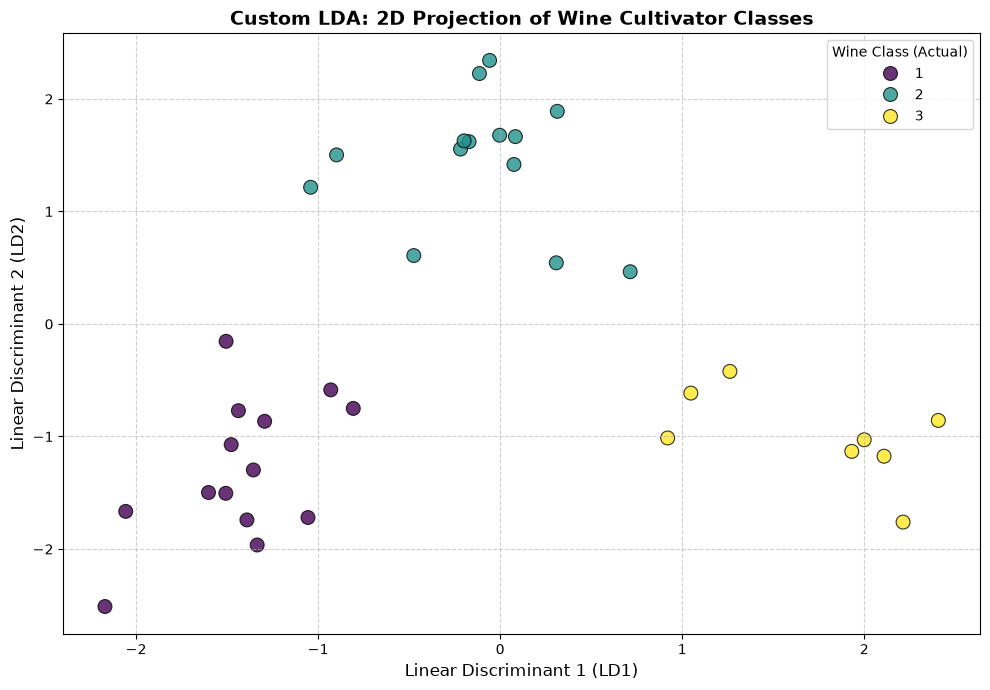

In [4]:
# Cluster Visualization 

# Plot a 2D Scatter Plot of the transformed testing data
plt.figure(figsize=(10, 7))

# Map the two extracted linear discriminants on the X and Y axes
sns.scatterplot(
    x=X_test_lda[:, 0], 
    y=X_test_lda[:, 1], 
    hue=y_test, 
    palette='viridis', 
    s=100, 
    edgecolor='k',
    alpha=0.8
)

plt.title('Custom LDA: 2D Projection of Wine Cultivator Classes', fontsize=14, fontweight='bold')
plt.xlabel('Linear Discriminant 1 (LD1)', fontsize=12)
plt.ylabel('Linear Discriminant 2 (LD2)', fontsize=12)
plt.legend(title='Wine Class (Actual)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()